# Ten-car ORCA-MPPI traffic jam in warehouse2

Ten car-like robots form two five-car queues facing each other across the central bottleneck of the same Bench-MR `warehouse2` map used by `rrt_connect_warehouse2_multiagent.ipynb`. The starts are four map units apart, with five cars heading east and five heading west. RRT-Connect plans a safe anchor for each car, and all agents then execute simultaneously with ORCA-MPPI. This is a stress case: sampled outcomes can vary, and an unfinished run is evidence of congestion rather than proof that the routes are impossible.

The pointed end and pale windshield are the **front**; the red bar is the **rear**. Planning, ORCA, and collision checks use a conservative circular radius that contains the drawn body at every heading. RRT-Connect anchors are position-only paths; the executed trajectories show what the car-like controller actually does. The animation's right panel stays on the bottleneck so the queue is visible.

After a native-code update, rebuild with `cmake --build build/release --target mppi_all -j2`, restart the Jupyter kernel, and run all cells. A running kernel keeps an already-imported `mppi_ca_cpp` binary loaded.

![Ten-car warehouse traffic jam](rrt_connect_warehouse2_car_like_traffic_jam.gif)


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Circle, Polygon as PolygonPatch
import numpy as np
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name in {'benchmarks', 'example'}:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'benchmarks'))
sys.path.insert(0, str(ROOT / 'example'))

from bench_mr import boundary_obstacles
from rrt_connect import RRTConnectPlanner
import dyn_models
from params_names import *
import utils

suite = json.loads((ROOT / 'benchmarks/bench_mr_tasks.json').read_text())
world = suite['worlds']['warehouse2']


## Editable opposing queues and car geometry

Each pose is `[x, y, heading]`, with heading in radians. Edit `LEFT_X`, `RIGHT_X`, or `LANE_Y` to move the queues; check that the cars still start outside the inflated obstacles and do not overlap. The body is contained by `ROBOT_RADIUS`, which is passed to RRT-Connect and ORCA-MPPI. `WHEELBASE` and `STEER_LIMIT` define the bicycle turn radius.


In [2]:
SEED = 42
LEFT_X = np.array([36.0, 40.0, 44.0, 48.0, 52.0])
RIGHT_X = np.array([100.0, 104.0, 108.0, 112.0, 116.0])
LANE_Y = -41.0
AGENT_NAMES = [f'E{i + 1}' for i in range(len(LEFT_X))] + [f'W{i + 1}' for i in range(len(RIGHT_X))]
CUSTOM_STARTS = np.array(
    [[x, LANE_Y, 0.0] for x in LEFT_X] +
    [[x, LANE_Y, np.pi] for x in RIGHT_X], dtype=float,
)
CUSTOM_GOALS = np.array(
    [[RIGHT_X[i], LANE_Y, 0.0] for i in range(len(LEFT_X))] +
    [[LEFT_X[i], LANE_Y, np.pi] for i in range(len(RIGHT_X))], dtype=float,
)

ROBOT_RADIUS = 0.70
CAR_LENGTH = 1.20
CAR_WIDTH = 0.65
WHEELBASE = 1.00
STEER_LIMIT = 0.60
STEER_RATE_LIMIT = 2.0
MAX_SPEED = 1.2
REVERSE_MAX_SPEED = 0.6
ACCEL_MAX = 1.0
BRAKE_MAX = 4.0
PLANNER_CLEARANCE = 0.15
JERK_MIN = -2.0
JERK_MAX = 2.0
DT = 0.1

if len(LEFT_X) != 5 or len(RIGHT_X) != 5:
    raise ValueError('The stress case uses five cars from each side')
if CUSTOM_STARTS.shape != CUSTOM_GOALS.shape or CUSTOM_STARTS.shape != (len(AGENT_NAMES), 3):
    raise ValueError('Provide one [x, y, heading] start and goal per car')
if not np.isfinite(CUSTOM_STARTS).all() or not np.isfinite(CUSTOM_GOALS).all():
    raise ValueError('Start and goal poses must be finite')
if np.hypot(CAR_LENGTH / 2, CAR_WIDTH / 2) > ROBOT_RADIUS:
    raise ValueError('The visible car body must fit inside the collision radius')
if WHEELBASE <= 0 or STEER_LIMIT <= 0 or STEER_LIMIT >= np.pi / 2:
    raise ValueError('Wheelbase and steering limit must define a finite turning radius')
start_distances = np.linalg.norm(
    CUSTOM_STARTS[:, None, :2] - CUSTOM_STARTS[None, :, :2], axis=2,
)
np.fill_diagonal(start_distances, np.inf)
if start_distances.min() <= 2 * ROBOT_RADIUS:
    raise ValueError('Starting car collision envelopes overlap')
print(f'{len(AGENT_NAMES)} cars on warehouse2; minimum initial center spacing '
      f'{start_distances.min():.2f}; bicycle turn radius '
      f'{WHEELBASE / np.tan(STEER_LIMIT):.2f}')


10 cars on warehouse2; minimum initial center spacing 4.00; bicycle turn radius 1.46


## RRT-Connect anchors through the same narrow passage

Dotted lines are raw RRT-Connect paths. Dashed lines are collision-checked shortcut paths passed to MPPI. Each obstacle is expanded by the circular body radius plus planning clearance. The colored start cars indicate travel direction.


In [3]:
planning_results = []
for agent_id, (start, goal) in enumerate(zip(CUSTOM_STARTS, CUSTOM_GOALS)):
    planner = RRTConnectPlanner(
        obstacles=world['obstacles'], bounds=world['bounds'],
        robot_radius=ROBOT_RADIUS, clearance=PLANNER_CLEARANCE,
        step_size=1.5, max_iterations=100_000, goal_sample_rate=0.05,
        smoothing_iterations=800, seed=SEED + agent_id,
    )
    result = planner.plan(start[:2], goal[:2])
    planning_results.append(result)
    length = sum(np.linalg.norm(np.subtract(b, a))
                 for a, b in zip(result.path, result.path[1:]))
    print(f'{AGENT_NAMES[agent_id]}: {result.iterations} RRT iterations, '
          f'{len(result.path)} anchor vertices, length {length:.1f}')
anchor_paths = [result.path for result in planning_results]


E1: 33 RRT iterations, 3 anchor vertices, length 64.2
E2: 11 RRT iterations, 3 anchor vertices, length 64.2
E3: 11 RRT iterations, 4 anchor vertices, length 64.4
E4: 51 RRT iterations, 3 anchor vertices, length 64.1
E5: 33 RRT iterations, 4 anchor vertices, length 64.7
W1: 24 RRT iterations, 3 anchor vertices, length 64.1
W2: 7 RRT iterations, 3 anchor vertices, length 64.1
W3: 10 RRT iterations, 3 anchor vertices, length 64.1
W4: 41 RRT iterations, 3 anchor vertices, length 64.1
W5: 10 RRT iterations, 4 anchor vertices, length 64.5


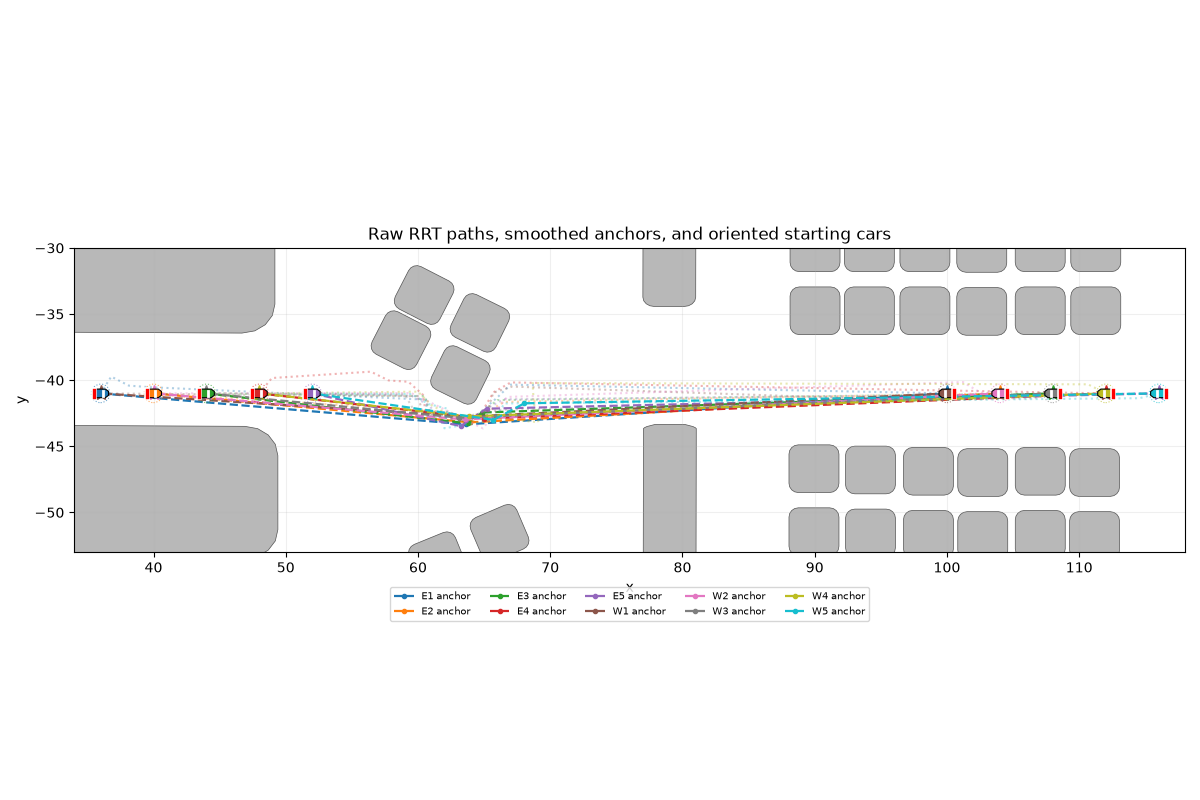

In [4]:
colors = plt.colormaps['tab10'](np.arange(len(AGENT_NAMES)))

def draw_world(ax):
    for vertices in world['obstacles']:
        ax.add_patch(PolygonPatch(vertices, closed=True, facecolor='0.72',
                                  edgecolor='0.32', linewidth=0.5))
    bounds = world['bounds']
    ax.set(xlim=(bounds[0], bounds[2]), ylim=(bounds[1], bounds[3]),
           aspect='equal', xlabel='x', ylabel='y')
    ax.grid(alpha=0.2)

def draw_car(ax, pose, color, alpha=1.0, safety_circle=False):
    """Draw a pointed front, pale windshield, and red rear at the car heading."""
    x, y, heading = pose[:3]
    rotation = np.array([[np.cos(heading), -np.sin(heading)],
                         [np.sin(heading),  np.cos(heading)]])
    def world_points(local):
        return np.asarray(local) @ rotation.T + [x, y]
    half_l, half_w = CAR_LENGTH / 2, CAR_WIDTH / 2
    body = world_points([[-half_l, -half_w], [0.30 * CAR_LENGTH, -half_w],
                         [half_l, -0.45 * half_w], [half_l, 0.45 * half_w],
                         [0.30 * CAR_LENGTH, half_w], [-half_l, half_w]])
    ax.add_patch(PolygonPatch(body, closed=True, facecolor=color,
                              edgecolor='black', linewidth=0.8, alpha=alpha, zorder=5))
    windshield = world_points([[0.12 * CAR_LENGTH, -0.65 * half_w],
                               [0.12 * CAR_LENGTH,  0.65 * half_w]])
    rear = world_points([[-0.88 * half_l, -0.75 * half_w],
                         [-0.88 * half_l,  0.75 * half_w]])
    ax.plot(windshield[:, 0], windshield[:, 1], color='white', linewidth=2.0,
            alpha=alpha, zorder=6)
    ax.plot(rear[:, 0], rear[:, 1], color='white', linewidth=4.0,
            alpha=alpha, zorder=6)
    ax.plot(rear[:, 0], rear[:, 1], color='red', linewidth=2.4,
            alpha=alpha, zorder=7)
    if safety_circle:
        ax.add_patch(Circle((x, y), ROBOT_RADIUS, fill=False, color=color,
                            linestyle=':', linewidth=0.8, alpha=0.65, zorder=4))

fig, ax = plt.subplots(figsize=(12, 8))
draw_world(ax)
for agent_id, (start, goal, result) in enumerate(zip(CUSTOM_STARTS, CUSTOM_GOALS, planning_results)):
    raw, anchor = np.asarray(result.raw_path), np.asarray(result.path)
    color = colors[agent_id]
    ax.plot(raw[:, 0], raw[:, 1], ':', color=color, alpha=0.35)
    ax.plot(anchor[:, 0], anchor[:, 1], '--o', color=color, linewidth=1.6,
            markersize=3, label=f'{AGENT_NAMES[agent_id]} anchor')
    draw_car(ax, start, color, safety_circle=True)
    ax.plot(*goal[:2], '*', color=color, markersize=11)
ax.set_title('Raw RRT paths, smoothed anchors, and oriented starting cars')
ax.set(xlim=(34, 118), ylim=(-53, -30))
ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.10), ncol=5)
fig.tight_layout()
plt.show()


## Run concurrent car-like ORCA-MPPI inference

State is `[x, y, heading, velocity, steering angle, acceleration]`; controls are `[jerk, steering rate]`. `LONGITUDINAL_ACCEL_MIN/MAX` bound signed acceleration, `STEERING_RATE_MAX` bounds steering rate, and the existing `DIFF_DRIVE_V_MIN/MAX` and `DIFF_DRIVE_W_MIN/MAX` bound velocity and steering angle. Every rollout integrates `a[k+1] = a[k] + j[k] * DT`, `v[k+1] = v[k] + a[k] * DT`, and `steering[k+1] = steering[k] + steering_rate[k] * DT`. `LONGITUDINAL_JERK_MIN/MAX` bound jerk at ±2 units/s³. Speed-limit headroom ensures acceleration can return to zero before saturation, including beyond the horizon. The first control of a new horizon uses the measured velocity, acceleration, and steering angle. Reverse is capped at 0.6 units/s; direction changes pass continuously through zero speed. The controller uses the circular collision envelope.

All ten cars must finish within 3.0 map units of their goal positions for `success=True`; goal headings are displayed but are not part of the stopping rule. This traffic stress case may hit the 600-step limit. The diagnostics below report the number of cars in the bottleneck, stopped cars, closest clearance, and unfinished cars, so a jam is distinguishable from a collision.

The jam uses a 2.5-second prediction horizon and a 5.0-second ORCA warning time and 0.15 map units of controller clearance so cars can begin jerk-limited braking before the bottleneck. The former acceleration-control profile used a shorter response window.

ORCA also reserves each moving car's jerk-limited stopping arc length plus one simulation step of travel as extra clearance. The drawn body and reported physical gaps still use `ROBOT_RADIUS`.

The dense warehouse queues use a forward cruise limit of 1.2 units/s and full ORCA avoidance responsibility, while reverse remains capped at 0.6. This reserves time and space for jerk-limited braking in the congested passage.

Quadratic jerk and steering-rate costs use the physically bounded rollout controls. Sampling standard deviations are 0.25 map units/s³ and 0.05 rad/s, below the unchanged hard limits of ±2.

Temporal costs `500 * sum((Δjerk)²)` and `1000 * sum((Δsteering_rate)²)` discourage alternating commands inside each rollout. The first change is measured from the previous executed command, including across horizons. These are soft costs, not another state or derivative limit.


In [5]:
AGENTS_NUM = len(AGENT_NAMES)
start_states = np.c_[CUSTOM_STARTS, np.zeros((AGENTS_NUM, 3))]
goal_states = np.c_[CUSTOM_GOALS, np.zeros((AGENTS_NUM, 3))]

agent_params = {
    AGENT_SIZE: ROBOT_RADIUS, VISIBILITY_RADIUS: 30.0,
    DIFF_DRIVE_V_MAX: MAX_SPEED, DIFF_DRIVE_V_MIN: -REVERSE_MAX_SPEED,
    LONGITUDINAL_ACCEL_MIN: -BRAKE_MAX, LONGITUDINAL_ACCEL_MAX: ACCEL_MAX,
    LONGITUDINAL_JERK_MIN: JERK_MIN, LONGITUDINAL_JERK_MAX: JERK_MAX,
    DIFF_DRIVE_W_MAX: STEER_LIMIT, DIFF_DRIVE_W_MIN: -STEER_LIMIT,
    STEERING_RATE_MAX: STEER_RATE_LIMIT,
}
agents_params = [agent_params.copy() for _ in range(AGENTS_NUM)]
agent_models = [dyn_models.CarLikeDyn(WHEELBASE) for _ in range(AGENTS_NUM)]
alg_params = {
    SAMPLE_BATCH_SIZE: 100, SAMPLE_TIME_STEPS: 26, TIME_STEP: DT,
    INIT_VALUE: np.zeros(2), CONTROL_MEAN: np.zeros(2),
    # Variances of [jerk, steering_rate]; standard deviations are 0.25 and 0.05.
    CONTROL_COV: np.diag([0.0625, 0.0025]),
    JERK_COST_WEIGHT: 300.0, STEERING_RATE_COST_WEIGHT: 300.0,
    JERK_CHANGE_COST_WEIGHT: 500.0, STEERING_RATE_CHANGE_COST_WEIGHT: 1000.0,
    RUNNING_COST_WEIGH: 300.0, TERMINAL_WEIGHT: 2000.0,
    SOFTMAX_TEMPERATURE: 0.25, MA_COST_EN: True,
    MA_DIST_WEIGHT: 1200.0, MA_COLLISION_WEIGHT: 1e7,
    MA_DIST_THREASHOLD: 4.0, USE_CAR_LIKE_DYN: True,
    DIST_BETWEEN_AXLES: WHEELBASE,
    K_ALPHA: -2.96, RAD_EPS: 0.15, VELOCITY_COST_WEIGHT: 0.5,
    TERMINAL_LOOKAHEAD_DISTANCE: 6.0, MA_EN_CLOSE_TO_GOAL_DIST: 1.0,
    MA_EN_CLOSE_TO_GOAL_TS: 3, ORCA_TIME_BOUNDARY: 5.0,
    ORCA_RESPONSIBILITY_FACTOR: 1.0, MA_EXCLUDE_COLLISION_TRAJ: True,
    VELOCITY_COST_CLOSE_TO_GOAL_DIST: 0.7, ANCHOR_PATH_WEIGHT: 2000.0,
    ANCHOR_HEADING_WEIGHT: 500.0, CONTROL_SMOOTHNESS_WEIGHT: 20.0,
}
exp_params = {EXP_TIME_STEP: DT, XY_GOAL_TOLERANCE: 3.0, MAX_EXP_STEPS: 600}

expanded_bounds = np.asarray(world['bounds']) + np.array([-1, -1, 1, 1]) * (ROBOT_RADIUS + 0.05)
controller_obstacles = world['obstacles'] + boundary_obstacles(expanded_bounds)
success, collisions, steps, duration, log_state = utils.launch_mppi(
    start_states, goal_states, AGENTS_NUM, agents_params, alg_params, exp_params,
    agent_models, seed=SEED, obstacles=controller_obstacles, anchor_paths=anchor_paths,
)
states = np.asarray(log_state)
xy = states[:, :, :2]
goal_errors = np.linalg.norm(xy[-1] - goal_states[:, :2], axis=1)
unfinished = goal_errors > exp_params[XY_GOAL_TOLERANCE]

# Count cars in the central passage and cars nearly stopped there.
CHOKE_BOUNDS = (60.0, -46.0, 85.0, -37.0)
xmin, ymin, xmax, ymax = CHOKE_BOUNDS
in_choke = ((xy[:, :, 0] >= xmin) & (xy[:, :, 0] <= xmax) &
            (xy[:, :, 1] >= ymin) & (xy[:, :, 1] <= ymax))
choke_counts = in_choke.sum(axis=1)
# Velocity and steering are physical state, not commanded pose increments.
speeds = states[1:, :, 3]
previous_speeds = states[:-1, :, 3]
accelerations = states[:, :, 5]
speed_rates = np.diff(states[:, :, 3], axis=0) / DT
np.testing.assert_allclose(speed_rates, accelerations[:-1], atol=1e-8)
steering_rates = np.diff(states[:, :, 4], axis=0) / DT
jerks = np.diff(accelerations, axis=0) / DT
# Raw differences measure chatter; they are diagnostics, not extra controls.
control_values = np.stack([jerks, steering_rates], axis=-1)
control_rms = np.sqrt(np.mean(control_values**2, axis=(0, 1)))
control_change_rms = np.sqrt(np.mean(np.diff(control_values, axis=0)**2, axis=(0, 1)))
print('RMS [jerk, steering_rate]:', np.round(control_rms, 4))
print('RMS successive-command changes:', np.round(control_change_rms, 4))
print(f'jerk near hard bounds: {np.mean((jerks <= 0.95 * JERK_MIN) | (jerks >= 0.95 * JERK_MAX)):.1%}')
max_acceleration = float(accelerations.max())
max_braking = float(-accelerations.min())
assert np.max(states[:, :, 3]) <= MAX_SPEED + 1e-6
assert np.min(states[:, :, 3]) >= -REVERSE_MAX_SPEED - 1e-6
assert accelerations.max() <= ACCEL_MAX + 1e-6
assert accelerations.min() >= -BRAKE_MAX - 1e-6
assert jerks.min() >= JERK_MIN - 1e-6
assert jerks.max() <= JERK_MAX + 1e-6
assert np.max(np.abs(states[:, :, 4])) <= STEER_LIMIT + 1e-6
assert np.max(np.abs(steering_rates)) <= STEER_RATE_LIMIT + 1e-6

reverse_steps = np.sum(speeds < -0.05, axis=0)
forward_after_reverse = []
for agent_id, name in enumerate(AGENT_NAMES):
    reverse_indices = np.flatnonzero(speeds[:, agent_id] < -0.05)
    if len(reverse_indices) and np.any(speeds[reverse_indices[-1] + 1:, agent_id] > 0.05):
        forward_after_reverse.append(name)
SLOW_SPEED = 0.2
slow_in_choke = np.r_[0, ((np.abs(speeds) < SLOW_SPEED) & in_choke[1:]).sum(axis=1)]
lookback = min(30, len(states) - 1)
recent_motion = np.linalg.norm(xy[-1] - xy[-1 - lookback], axis=1)
stalled = unfinished & (recent_motion < 0.5)

closest = (np.inf, None, None, None)
for first in range(AGENTS_NUM):
    for second in range(first + 1, AGENTS_NUM):
        center_distances = np.linalg.norm(xy[:, first] - xy[:, second], axis=1)
        closest_step = int(np.argmin(center_distances))
        gap = float(center_distances[closest_step] - 2 * ROBOT_RADIUS)
        if gap < closest[0]:
            closest = (gap, first, second, closest_step)

print(f'success={success}, collisions={collisions}, steps={steps}, wall time={duration:.2f}s')
print(f'measured a range=[{-max_braking:.2f}, {max_acceleration:.2f}] units/s²; '
      f'max steering rate={np.max(np.abs(steering_rates)):.2f} rad/s')
print(f'measured jerk range=[{jerks.min():.2f}, {jerks.max():.2f}] units/s³; '
      f'max acceleration step={np.max(np.abs(np.diff(accelerations, axis=0))):.3f}')
print(f'reverse steps by car: {dict(zip(AGENT_NAMES, reverse_steps.tolist()))}')
print(f'reversed then moved forward: {forward_after_reverse}')
print(f'cars in bottleneck: peak={choke_counts.max()}/{AGENTS_NUM}, final={choke_counts[-1]}/{AGENTS_NUM}')
print(f'peak nearly stopped in bottleneck (<{SLOW_SPEED} units/s): {slow_in_choke.max()}')
print(f'closest circular-envelope gap: {closest[0]:.3f} '
      f'({AGENT_NAMES[closest[1]]}/{AGENT_NAMES[closest[2]]}, step {closest[3]})')
print(f'unfinished cars: {[AGENT_NAMES[i] for i in np.flatnonzero(unfinished)]}')
print(f'stalled unfinished cars (less than 0.5 units in the last 3 s): '
      f'{[AGENT_NAMES[i] for i in np.flatnonzero(stalled)]}')
for name, error in zip(AGENT_NAMES, goal_errors):
    print(f'{name}: final XY error={error:.2f}')


RMS [jerk, steering_rate]: [0.6401 0.1664]
RMS successive-command changes: [0.6937 0.215 ]
jerk near hard bounds: 5.6%
success=False, collisions=0.0, steps=600, wall time=395.75s
measured a range=[-1.51, 0.68] units/s²; max steering rate=0.81 rad/s
measured jerk range=[-2.00, 2.00] units/s³; max acceleration step=0.200
reverse steps by car: {'E1': 25, 'E2': 10, 'E3': 0, 'E4': 2, 'E5': 9, 'W1': 0, 'W2': 0, 'W3': 0, 'W4': 0, 'W5': 20}
reversed then moved forward: ['E2', 'E5']
cars in bottleneck: peak=10/10, final=10/10
peak nearly stopped in bottleneck (<0.2 units/s): 10
closest circular-envelope gap: 0.304 (E4/W1, step 495)
unfinished cars: ['E1', 'E2', 'E3', 'E4', 'E5', 'W1', 'W2', 'W3', 'W4', 'W5']
stalled unfinished cars (less than 0.5 units in the last 3 s): ['E1', 'E2', 'E3', 'E4', 'E5', 'W1', 'W2', 'W3', 'W4', 'W5']
E1: final XY error=39.58
E2: final XY error=41.79
E3: final XY error=44.05
E4: final XY error=46.34
E5: final XY error=46.98
W1: final XY error=31.42
W2: final XY erro

## Executed paths, queue buildup, and animation

The route plot shows the actual car trajectories and final oriented bodies. The close-up covers the bottleneck. Its companion time series counts cars in the rectangle marked by `CHOKE_BOUNDS` and those traveling slower than 0.2 map units/s there. The raw state and control charts show all cars: velocity, signed acceleration, jerk, and steering angle; dashed lines are physical limits. A car may reach its goal before the others and then move again because the simulator stops only when **all** cars satisfy the goal tolerance in the same step.


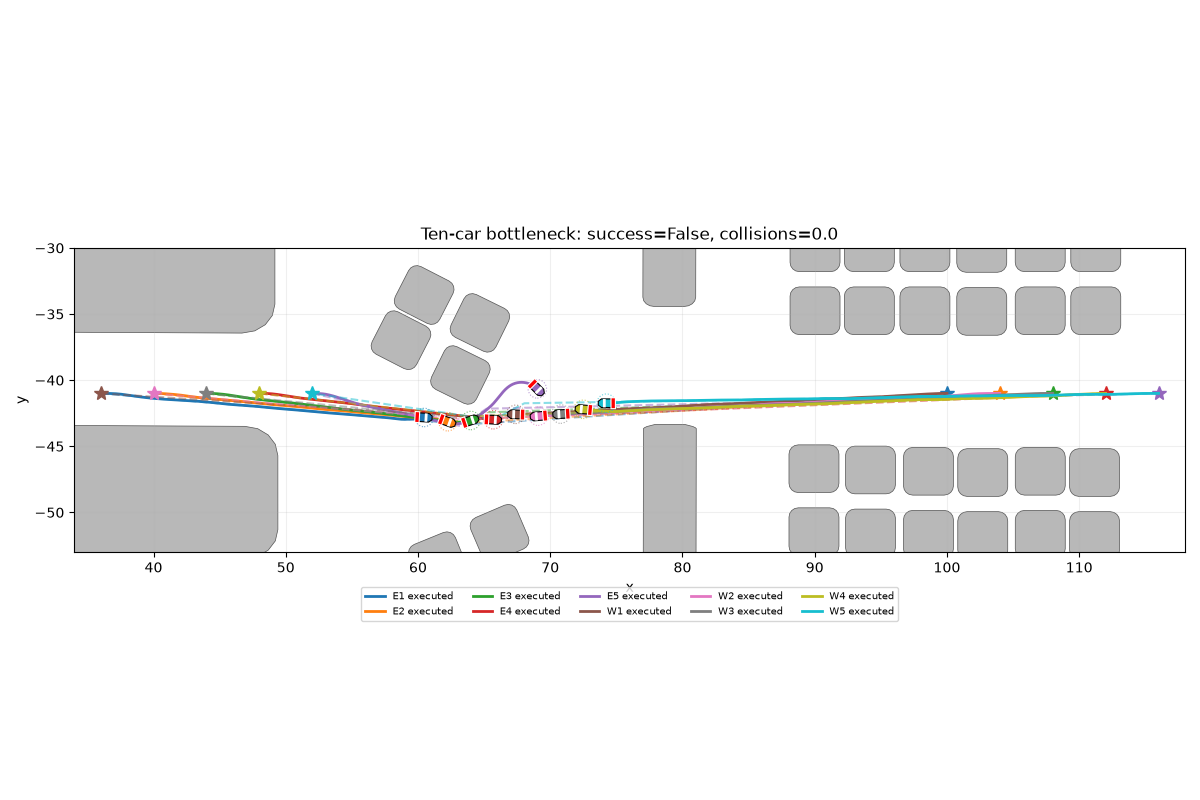

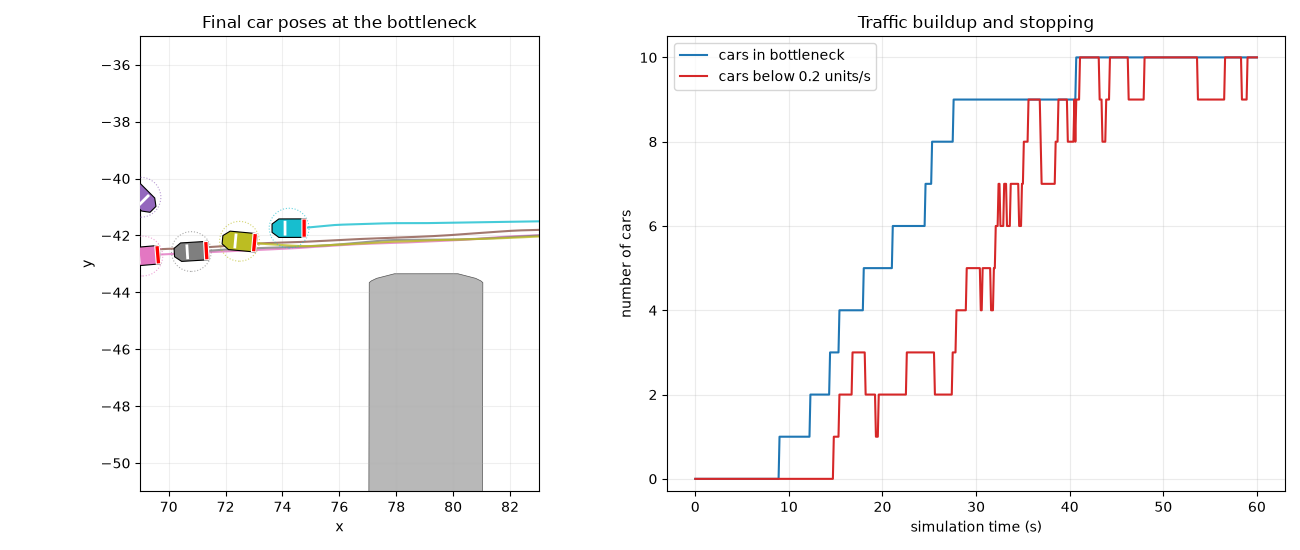

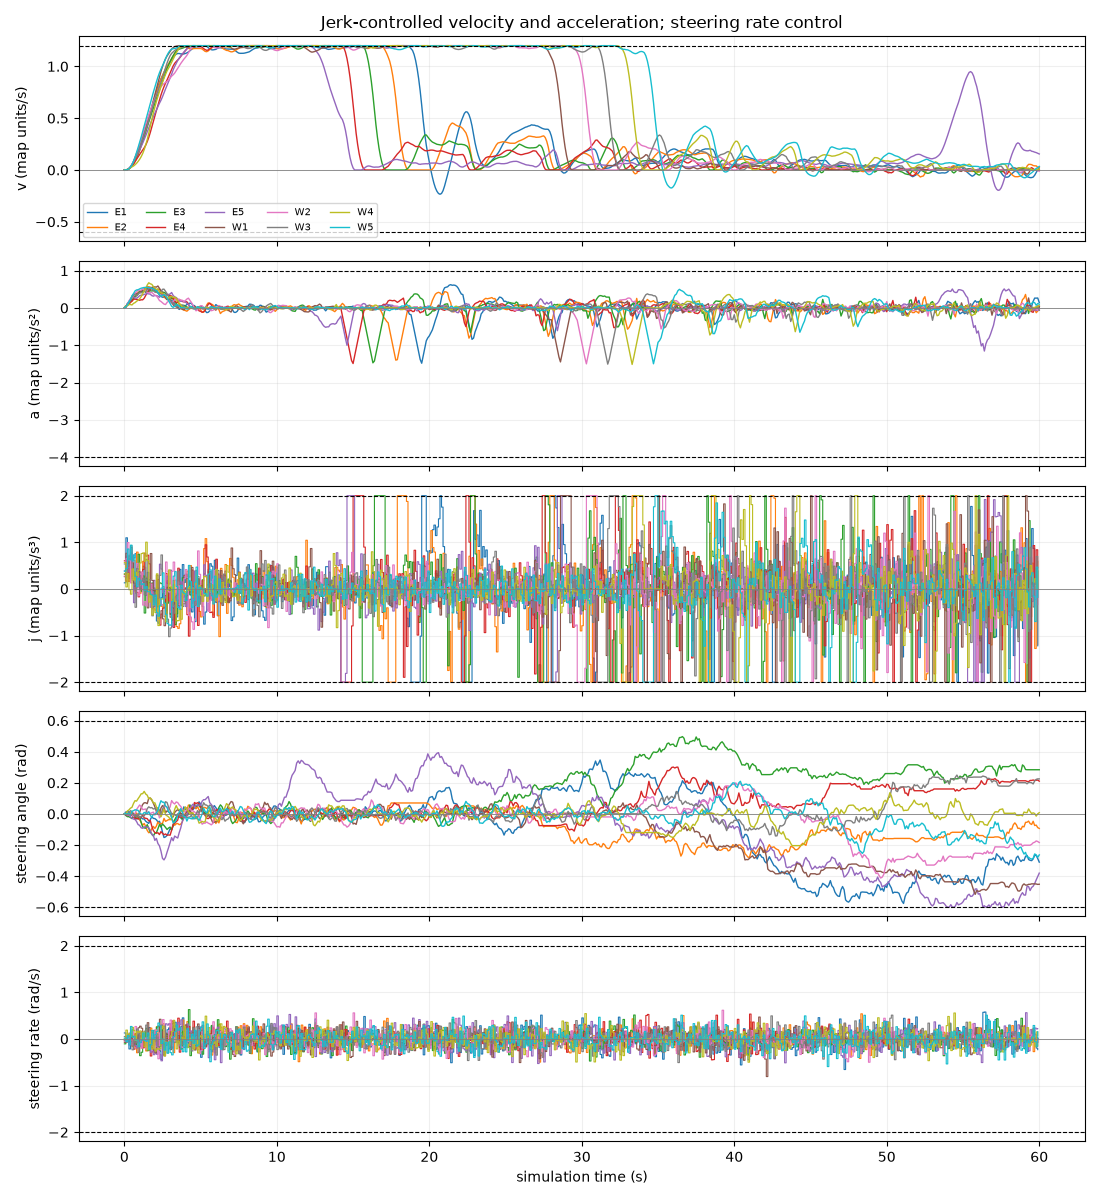

In [6]:
fig, ax = plt.subplots(figsize=(12, 8))
draw_world(ax)
for agent_id, (goal, result) in enumerate(zip(CUSTOM_GOALS, planning_results)):
    color = colors[agent_id]
    anchor = np.asarray(result.path)
    ax.plot(anchor[:, 0], anchor[:, 1], '--', color=color, alpha=0.5)
    ax.plot(xy[:, agent_id, 0], xy[:, agent_id, 1], color=color,
            linewidth=2, label=f'{AGENT_NAMES[agent_id]} executed')
    draw_car(ax, states[-1, agent_id], color, safety_circle=True)
    ax.plot(*goal[:2], '*', color=color, markersize=10)
ax.set(xlim=(34, 118), ylim=(-53, -30))
ax.set_title(f'Ten-car bottleneck: success={success}, collisions={collisions}')
ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.10), ncol=5)
fig.tight_layout()
plt.show()

fig, (ax_close, ax_queue) = plt.subplots(1, 2, figsize=(13, 5.5))
draw_world(ax_close)
ax_close.set(xlim=(69, 83), ylim=(-51, -35))
for agent_id in range(AGENTS_NUM):
    color = colors[agent_id]
    ax_close.plot(xy[:, agent_id, 0], xy[:, agent_id, 1], color=color, alpha=0.8)
    draw_car(ax_close, states[-1, agent_id], color, safety_circle=True)
ax_close.set_title('Final car poses at the bottleneck')
times = np.arange(len(states)) * DT
ax_queue.plot(times, choke_counts, label='cars in bottleneck', color='tab:blue')
ax_queue.plot(times, slow_in_choke, label=f'cars below {SLOW_SPEED} units/s', color='tab:red')
ax_queue.set(xlabel='simulation time (s)', ylabel='number of cars',
             ylim=(-0.3, AGENTS_NUM + 0.5), title='Traffic buildup and stopping')
ax_queue.grid(alpha=0.25)
ax_queue.legend()
fig.tight_layout()
plt.show()

# Raw state/control differences: no smoothing or moving averages.
fig, axes = plt.subplots(5, 1, figsize=(11, 12), sharex=True)
state_times = np.arange(len(states)) * DT
control_times = state_times[:-1]
for agent_id, agent_name in enumerate(AGENT_NAMES):
    color = colors[agent_id]
    axes[0].plot(state_times, states[:, agent_id, 3], color=color, label=agent_name, linewidth=1)
    axes[1].plot(state_times, accelerations[:, agent_id], color=color, linewidth=1)
    axes[2].step(control_times, jerks[:, agent_id], where='post', color=color, linewidth=0.8)
    axes[3].plot(state_times, states[:, agent_id, 4], color=color, linewidth=1)
    axes[4].step(control_times, steering_rates[:, agent_id], where='post', color=color, linewidth=0.8)
axes[0].axhline(MAX_SPEED, color='black', linestyle='--', linewidth=0.8)
axes[0].axhline(-REVERSE_MAX_SPEED, color='black', linestyle='--', linewidth=0.8)
axes[0].set(ylabel='v (map units/s)', title='Jerk-controlled velocity and acceleration; steering rate control')
axes[0].legend(fontsize=7, ncol=5)
axes[1].axhline(ACCEL_MAX, color='black', linestyle='--', linewidth=0.8)
axes[1].axhline(-BRAKE_MAX, color='black', linestyle='--', linewidth=0.8)
axes[1].set(ylabel='a (map units/s²)')
axes[2].axhline(JERK_MAX, color='black', linestyle='--', linewidth=0.8)
axes[2].axhline(JERK_MIN, color='black', linestyle='--', linewidth=0.8)
axes[2].set(ylabel='j (map units/s³)')
axes[3].axhline(STEER_LIMIT, color='black', linestyle='--', linewidth=0.8)
axes[3].axhline(-STEER_LIMIT, color='black', linestyle='--', linewidth=0.8)
axes[3].set(ylabel='steering angle (rad)')
axes[4].axhline(STEER_RATE_LIMIT, color='black', linestyle='--', linewidth=0.8)
axes[4].axhline(-STEER_RATE_LIMIT, color='black', linestyle='--', linewidth=0.8)
axes[4].set(ylabel='steering rate (rad/s)', xlabel='simulation time (s)')
for ax in axes:
    ax.axhline(0, color='gray', linewidth=0.6)
    ax.grid(alpha=0.2)
fig.tight_layout()
DYNAMICS_PLOT_PATH = ROOT / 'benchmarks/rrt_connect_warehouse2_car_like_traffic_jam_dynamics.png'
fig.savefig(DYNAMICS_PLOT_PATH, dpi=160)
plt.show()


In [7]:
fig, (ax_map, ax_close) = plt.subplots(
    1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1.7, 1]}
)
frame_indices = np.unique(np.linspace(0, len(states) - 1, min(100, len(states))).astype(int))

def animate(frame_number):
    state_index = int(frame_indices[frame_number])
    ax_map.clear()
    ax_close.clear()
    draw_world(ax_map)
    draw_world(ax_close)
    ax_close.set(xlim=(69, 83), ylim=(-51, -35))
    for agent_id, (goal, anchor_path) in enumerate(zip(CUSTOM_GOALS, anchor_paths)):
        color = colors[agent_id]
        anchor = np.asarray(anchor_path)
        for ax in (ax_map, ax_close):
            ax.plot(anchor[:, 0], anchor[:, 1], '--', color=color,
                    alpha=0.35, linewidth=1.1)
            ax.plot(xy[:state_index + 1, agent_id, 0],
                    xy[:state_index + 1, agent_id, 1],
                    color=color, linewidth=1.6)
            draw_car(ax, states[state_index, agent_id], color, safety_circle=True)
            ax.plot(*goal[:2], '*', color=color, markersize=9)
    ax_map.set_title(f'Ten-car ORCA-MPPI: step {state_index}/{len(states) - 1}')
    ax_close.set_title(f'Bottleneck: {choke_counts[state_index]} cars, '
                       f'{slow_in_choke[state_index]} nearly stopped')

animation = FuncAnimation(fig, animate, frames=len(frame_indices), interval=100)
GIF_PATH = ROOT / 'benchmarks/rrt_connect_warehouse2_car_like_traffic_jam.gif'
animation.save(GIF_PATH, writer=PillowWriter(fps=10))
plt.close(fig)
display(Image(filename=str(GIF_PATH)))


<IPython.core.display.Image object>


Acceleration, velocity, and steering angle are integrated from the current six-state vehicle model. Hard jerk and steering-rate limits still apply inside every rollout. Quadratic costs of `300 * sum(j²)` and `300 * sum(steering_rate²)`, with sampling variances `[0.0625, 0.0025]`, penalize control effort. Additional costs of `500 * sum((Δjerk)²)` and `1000 * sum((Δsteering_rate)²)` penalize command changes, including at horizon boundaries. The plots show raw state and control traces without filters.
